In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Define the project directory explicitly
PROJECT_ROOT = Path(r"C:\Main_Drive\work\workarea\projects\research_manuscript_quality_analyzer")

# Load training data
train_path = PROJECT_ROOT/"data"/"raw"/"cola_train.csv"


df_train = pd.read_csv(train_path)

print(df_train.info())
df_train.head()


<class 'pandas.DataFrame'>
RangeIndex: 8551 entries, 0 to 8550
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   sentence  8551 non-null   str  
 1   label     8551 non-null   int64
 2   idx       8551 non-null   int64
dtypes: int64(2), str(1)
memory usage: 540.4 KB
None


,sentence,label,idx
0,"Our friends won't buy this analysis, let alone...",1,0
1,One more pseudo generalization and I'm giving up.,1,1
2,One more pseudo generalization or I'm giving up.,1,2
3,"The more we study verbs, the crazier they get.",1,3
4,Day by day the facts are getting murkier.,1,4


Lets Check the Missing counts and duplicates rows 

In [9]:
missing_counts = df_train.isnull().sum()
duplicate_rows = df_train.duplicated().sum()

print(missing_counts)
print(duplicate_rows)

sentence    0
label       0
idx         0
dtype: int64
0


so we found 0 missing values and duplicated rows, lets figure out weather dataset contains duplicate sentence or not


In [27]:
# Check empty sentences
print((df_train["sentence"].str.strip() == "").sum())

# Check sentences with leading or trailing spaces
print((df_train["sentence"] != df_train["sentence"].str.strip()).sum())

# Check duplicated sentences 
df_train["sentence"].duplicated().sum()

0
0


np.int64(19)

In [20]:
duplicate_rows = df_train[df_train["sentence"].duplicated(keep=False)].sort_values("sentence")

In [37]:
label_summary = duplicate_rows.groupby("sentence").agg(occurrences=("label", "size"),unique_labels = ("label","nunique"),)
label_summary

,occurrences,unique_labels
sentence,,
Can he not have been working?,2,2
He left.,2,1
He seems intelligent to study medicine.,2,2
He walked right the wall.,2,2
I hit the ball.,2,1
I've got to try and find that screw.,2,1
Jennifer craned her arm.,2,1
John is easy to please.,2,1
John wrote books.,2,2


In [45]:
# Separate consistent and conflicting groups
conflicts = label_summary[
    label_summary["unique_labels"] > 1
]

consistent_duplicates = label_summary[
    label_summary["unique_labels"] == 1
]

print(len(conflicts))
print(len(consistent_duplicates))

11
8


We found 19 groups of repeated sentences: 8 have the same label, while 11 have different labels. We will check these duplicates and decide how to handle them before training our model.

#### perform eda on target 

label
0    2528
1    6023
Name: count, dtype: int64


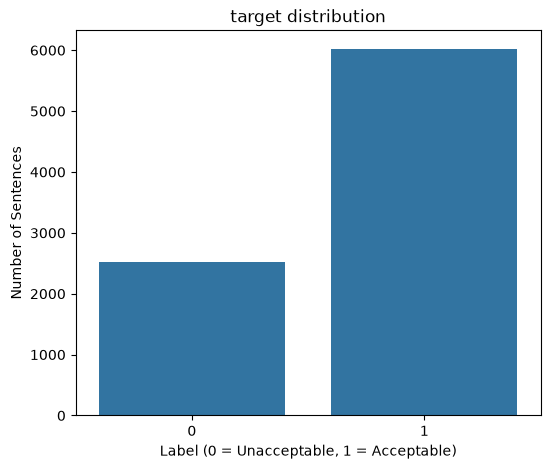

In [21]:
print(df_train["label"].value_counts().sort_index())

# Visualize label distribution
plt.figure(figsize=(6,5))
plt.title("target distribution")
plt.xlabel("Label (0 = Unacceptable, 1 = Acceptable)")
plt.ylabel("Number of Sentences")
sns.countplot(data=df_train,x="label")
plt.show()

The dataset is imbalanced, with more acceptable sentences (label 1) than unacceptable sentences (label 0). We will use suitable evaluation metrics to assess both classes.

In [ ]:
df_train["word_count"] = df_train["sentence"].apply(
    lambda text: len(text.split())
)

print(
    df_train.groupby("label")["word_count"]
    .agg(["mean", "median", "min", "max"])
)

['sentence', 'label', 'idx', 'word_count']
                                            sentence  label  idx  word_count
0  Our friends won't buy this analysis, let alone...      1    0          13
1  One more pseudo generalization and I'm giving up.      1    1           8
2   One more pseudo generalization or I'm giving up.      1    2           8


## EDA Summary and Preprocessing Decisions

### 1. **Duplicate Sentences**
- **Finding:** We found duplicate sentences, including some with conflicting labels.
- **Decision:** Do not remove duplicates blindly. Keep the original dataset unchanged and investigate conflicting labels before deciding how to handle them.
- **Why:** Removing duplicates without checking their labels could discard useful information or hide inconsistencies in the data.

### 2. **Class Distribution**
- **Finding:** The dataset is imbalanced, with more acceptable sentences (`1`) than unacceptable sentences (`0`).
- **Decision:** Keep the original class distribution initially and compare model performance using suitable evaluation metrics.
- **Why:** Automatically balancing the dataset could remove useful examples or change the original data distribution.

### 3. **Missing Values**
- **Finding:** No missing values were found in the training dataset.
- **Decision:** No missing-value treatment is required at this stage.
- **Why:** There are no missing entries to impute or remove.

### 4. **Empty Sentences and Whitespace**
- **Finding:** No empty sentences or sentences with leading or trailing whitespace were found.
- **Decision:** No additional cleaning is required for these issues in the current training data.
- **Why:** Unnecessary cleaning can add complexity without improving data quality.

### 5. **Sentence Length**
- **Finding:** Both classes have similar average and median word counts.
- **Decision:** Do not use word count as the only predictor of linguistic acceptability. Keep it as an optional feature for later experiments.
- **Why:** Sentence length alone may not distinguish acceptable sentences from unacceptable ones.

### 6. **Text Preprocessing Strategy**
- **Decision:** Start with lowercase conversion and **TF-IDF using unigrams and bigrams** for the traditional machine learning baseline. Do not remove stopwords or apply stemming or lemmatization initially.
- **Why:** Function words, grammatical structure, and word order can help identify linguistic acceptability. Removing or modifying words may discard useful information.

### 7. **Evaluation Strategy**
- **Decision:** Evaluate the baseline using **accuracy, precision, recall, F1-score, and a confusion matrix**. Pay particular attention to performance on the minority class.
- **Why:** Accuracy alone can hide poor performance on the less frequent class.

### **Conclusion**
The initial EDA identified class imbalance and duplicate sentences with conflicting labels as the main issues requiring attention. We will build a TF-IDF and Logistic Regression baseline first, then compare preprocessing choices and model performance before moving to a fine-tuned DistilBERT model.